In [1]:
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram
import matplotlib.pyplot as plt

# Initialize simulator and shots count
simulator = AerSimulator()
shots = 100

Part A Circuit (Correlated Outcomes):


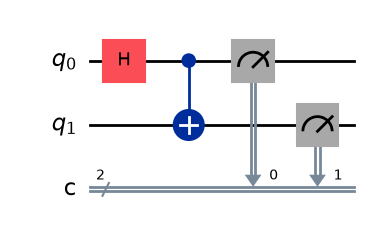

Part A Counts (100 shots): {'11': 51, '00': 49}


In [2]:
# Part A: Circuit with correlated outcomes (00 and 11)
qc_a = QuantumCircuit(2, 2)
qc_a.h(0)           # Puts qubit 0 into superposition
qc_a.cx(0, 1)       # Entangles qubit 1 with qubit 0
qc_a.measure([0, 1], [0, 1])

# Draw Circuit A
print("Part A Circuit (Correlated Outcomes):")
display(qc_a.draw('mpl'))

# Run for 100 shots
result_a = simulator.run(qc_a, shots=shots).result()
counts_a = result_a.get_counts()
print("Part A Counts (100 shots):", counts_a)

Part B Circuit (Opposite Outcomes):


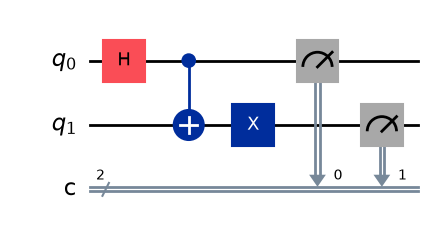

Part B Counts (100 shots): {'10': 52, '01': 48}


In [3]:
# Part B: Circuit with opposite outcomes (01 and 10)
# Uses 3 gates total before measurement (constraint: <= 4 gates)
qc_b = QuantumCircuit(2, 2)
qc_b.h(0)           # Superposition on qubit 0
qc_b.cx(0, 1)       # Entanglement
qc_b.x(1)           # Bit-flip switch: flips qubit 1 to reverse correlation
qc_b.measure([0, 1], [0, 1])

# Draw Circuit B
print("Part B Circuit (Opposite Outcomes):")
display(qc_b.draw('mpl'))

# Run for 100 shots
result_b = simulator.run(qc_b, shots=shots).result()
counts_b = result_b.get_counts()
print("Part B Counts (100 shots):", counts_b)

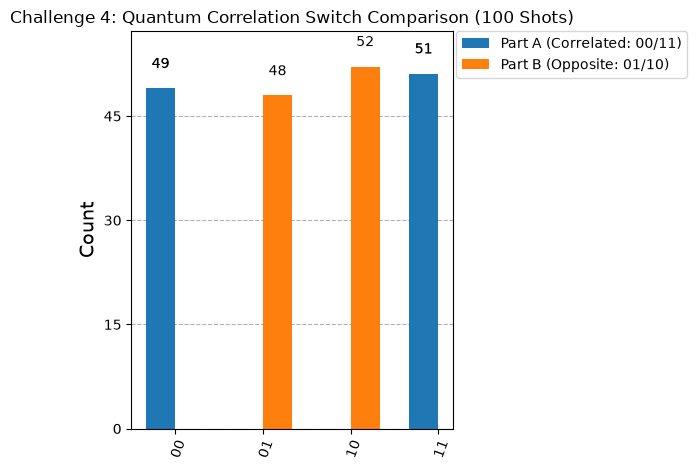

In [4]:
# Plot side-by-side histogram comparison
fig = plot_histogram(
    [counts_a, counts_b],
    legend=['Part A (Correlated: 00/11)', 'Part B (Opposite: 01/10)'],
    title="Challenge 4: Quantum Correlation Switch Comparison (100 Shots)"
)
display(fig)